<a href="https://colab.research.google.com/github/andresschill93-lab/analisis-educativo-mendoza/blob/main/TP_2_productos_de_detailing.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px

np.random.seed(42)

# Productos y su precio unitario (en pesos, inventados)
productos = {
    "Shampoo para autos": 4500,
    "Cera en pasta": 12000,
    "Paño de microfibra": 3000,
    "Limpiador de llantas": 6500,
    "Revividor de plásticos": 7000,
    "Pulidor": 15000,
}

# Último año: 12 meses (octubre 2025 a septiembre 2026)
meses = pd.date_range("2025-10-01", "2026-09-01", freq="MS")

def generar_ventas(franquicia, base):
    filas = []
    for mes in meses:
        for producto, precio in productos.items():
            unidades = int(np.random.normal(base, base * 0.2))
            filas.append([franquicia, mes, producto, unidades, precio])
    return pd.DataFrame(filas, columns=["franquicia", "mes", "producto", "unidades", "precio"])

# Mendoza vende menos | Córdoba vende más
mendoza = generar_ventas("Mendoza", base=40)
cordoba = generar_ventas("Córdoba", base=100)

print(mendoza.shape, cordoba.shape)
mendoza.head()

(72, 5) (72, 5)


,franquicia,mes,producto,unidades,precio
0,Mendoza,2025-10-01,Shampoo para autos,43,4500
1,Mendoza,2025-10-01,Cera en pasta,38,12000
2,Mendoza,2025-10-01,Paño de microfibra,45,3000
3,Mendoza,2025-10-01,Limpiador de llantas,52,6500
4,Mendoza,2025-10-01,Revividor de plásticos,38,7000


In [5]:
# Unir las dos tablas una debajo de la otra
df = pd.concat([mendoza, cordoba], ignore_index=True)

# Columna nueva: cuánto dinero entró por cada fila
df["ingreso"] = df["unidades"] * df["precio"]

# Revisión rápida de calidad
print(df.shape)
print(df.isna().sum())                          # nulos por columna
print("Duplicados:", df.duplicated().sum())
print("Unidades negativas:", (df["unidades"] < 0).sum())
df.info()

(144, 6)
franquicia    0
mes           0
producto      0
unidades      0
precio        0
ingreso       0
dtype: int64
Duplicados: 0
Unidades negativas: 0
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 144 entries, 0 to 143
Data columns (total 6 columns):
 #   Column      Non-Null Count  Dtype         
---  ------      --------------  -----         
 0   franquicia  144 non-null    object        
 1   mes         144 non-null    datetime64[ns]
 2   producto    144 non-null    object        
 3   unidades    144 non-null    int64         
 4   precio      144 non-null    int64         
 5   ingreso     144 non-null    int64         
dtypes: datetime64[ns](1), int64(3), object(2)
memory usage: 6.9+ KB


In [6]:
df.dtypes

,0
franquicia,object
mes,datetime64[ns]
producto,object
unidades,int64
precio,int64
ingreso,int64


franquicia
Córdoba    57370000
Mendoza    22507000
Name: ingreso, dtype: int64


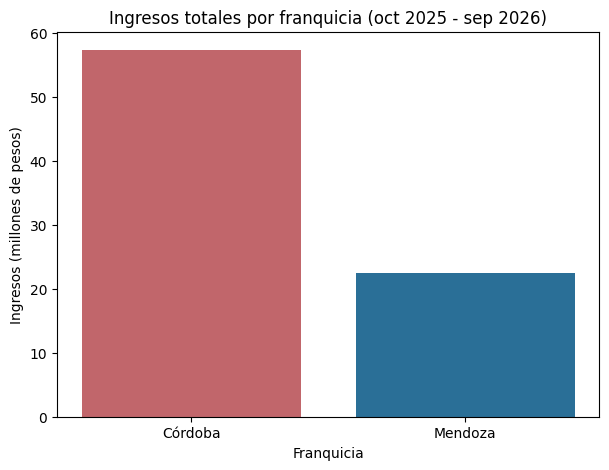

In [7]:
# 1) Sumar los ingresos de cada franquicia
totales = df.groupby("franquicia")["ingreso"].sum()
print(totales)

# 2) Pasar a millones de pesos para que el eje se lea fácil
totales_millones = totales / 1_000_000

# 3) Dibujar las barras
plt.figure(figsize=(7, 5))
plt.bar(totales_millones.index, totales_millones.values, color=["#c1666b", "#2a6f97"])
plt.title("Ingresos totales por franquicia (oct 2025 - sep 2026)")
plt.xlabel("Franquicia")
plt.ylabel("Ingresos (millones de pesos)")
plt.savefig("grafico_matplotlib.png", dpi=150, bbox_inches="tight")
plt.show()

               producto franquicia  ingreso
0         Cera en pasta    Córdoba  13.7280
1         Cera en pasta    Mendoza   5.3880
2  Limpiador de llantas    Córdoba   7.9040
3  Limpiador de llantas    Mendoza   2.9575
4    Paño de microfibra    Córdoba   3.3450


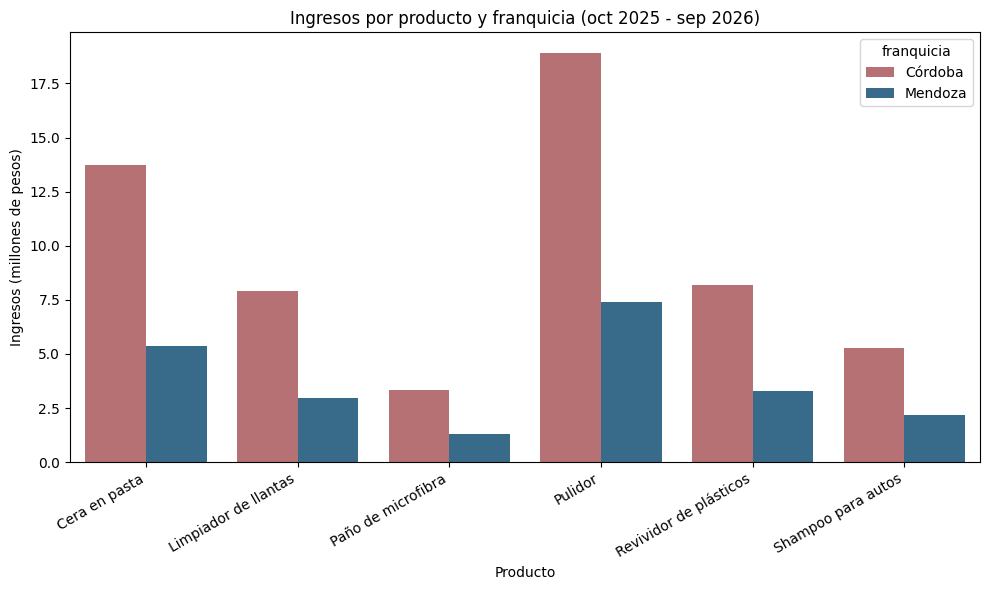

In [8]:
# 1) Sumar ingresos por producto y por franquicia
ventas_producto = df.groupby(["producto", "franquicia"], as_index=False)["ingreso"].sum()

# 2) Pasar a millones de pesos
ventas_producto["ingreso"] = ventas_producto["ingreso"] / 1_000_000
print(ventas_producto.head())

# 3) Dibujar con seaborn
plt.figure(figsize=(10, 6))
sns.barplot(data=ventas_producto, x="producto", y="ingreso", hue="franquicia",
            palette={"Córdoba": "#c1666b", "Mendoza": "#2a6f97"})
plt.title("Ingresos por producto y franquicia (oct 2025 - sep 2026)")
plt.xlabel("Producto")
plt.ylabel("Ingresos (millones de pesos)")
plt.xticks(rotation=30, ha="right")   # inclina los nombres para que no se pisen
plt.tight_layout()
plt.savefig("grafico_seaborn.png", dpi=150)
plt.show()

In [9]:
# 1) Sumar ingresos por mes y por franquicia
mensual = df.groupby(["mes", "franquicia"], as_index=False)["ingreso"].sum()
mensual["ingreso"] = mensual["ingreso"] / 1_000_000   # millones de pesos

# 2) Gráfico de líneas interactivo
fig = px.line(
    mensual, x="mes", y="ingreso", color="franquicia", markers=True,
    color_discrete_map={"Córdoba": "#c1666b", "Mendoza": "#2a6f97"},
    title="Ingresos mensuales por franquicia (oct 2025 - sep 2026)",
    labels={"mes": "Mes", "ingreso": "Ingresos (millones de pesos)", "franquicia": "Franquicia"},
)
fig.update_layout(hovermode="x unified")   # muestra las dos franquicias juntas al pasar el mouse
fig.show()